# 4. GOTOBI EFFECT · RECONCILIATION

Closing notebook of the **USDJPY Gotobi** edge: does what the research engine *decides and measures* match what will run in the MT5 EA? Same role as notebook 04 of the Monday edge (engine vs EA log), extended with the Gotobi-specific risks: **calendar** (Japanese bank days), **clock** (MT5 server time + US DST) and **fills / lots**.

### WHAT IS CHECKED
1. **Engine decisions** (`signal_table`): trades per year, data losses, engine quality gate.
2. **Independent calendar**: `gotobi_calendar` (numpy busday) vs a plain-`datetime` re-implementation (`independent_gotobi_dates`).
3. **Clock / DST**: entry and exit in server time per season, round-trip conversion, weekly-open structure, and the EA spec (what the EA must hardcode or read from the exported calendar).
4. **EA log vs engine**: decision, reason and spread per Gotobi date (inputs below; skipped cleanly if the file is missing).
5. **Fills** (optional): EA deals vs engine trades, slippage in bps.
6. **CFD lots**: lot rounding at `CAPITAL`, trades lost to the minimum lot, hard limit with real lots.
7. **PASS / FAIL registry** and **save** (`04_reconciliation.json`).

Notebooks 01-03 are not required to run first, but `03_validation.json` is read (if present) to show what is being carried to production.

In [1]:
VARIANT = "v1_axi_usdjpy"       # variants/<name>.yaml
CAPITAL = 10_000.0          # account capital (USD) for the lot-sizing check

# ---- EA decision log (one row per Gotobi date; the engine's signal_table has the same shape) ----
LOG_PATH = r"../../data/Reconcilation/Gotobi/gotobi_log.csv"   # None or a missing file -> section 4 is skipped
LOG_COLS = ["date", "spread_points", "decision", "reason"]      # no header in the file (set LOG_HEADER=0 if it has one)
LOG_SEP, LOG_HEADER = ";", None
LOG_BUY = "BUY"             # decision value that means "trade taken"
SPREAD_TOL_PIPS = 0.1       # tolerated |EA spread - engine feed spread|

# ---- EA deals export (optional, section 5): None to skip ----
DEALS_PATH = r"../../data/Reconcilation/Gotobi/gotobi_trades.csv"
DEAL_COLS = dict(entry_time="time_in", exit_time="time_out", entry_price="price_in", exit_price="price_out")
DEAL_SEP, DEAL_TIME_MODE = ";", "mt5_server_ny"   # deal times are MT5 server time ("utc" if already UTC)
SLIP_TOL_BPS = 1.0          # tolerated median |entry slippage| and |exit slippage| (bps)

## 1. IMPORTS AND CONFIG

In [2]:
import sys, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_edge_dir(start=None):
    """Folder that holds BOTH variants/ and gotobi_engine.py (notebooks, engine, utils and variants/ live together).
    Looks in cwd and its parents, then one or two levels below each of them."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        for cand in (base, *base.glob("*"), *base.glob("*/*")):
            if cand.is_dir() and (cand / "variants").is_dir() and (cand / "gotobi_engine.py").is_file():
                return cand
    raise FileNotFoundError(
        f"Could not find a folder with 'variants/' AND 'gotobi_engine.py' near {here}. "
        "Put gotobi_engine.py, gotobi_utils.py and variant_config.py next to variants/ (02_strategy_development/Gotobi/).")

EDGE_DIR = find_edge_dir()
if str(EDGE_DIR) not in sys.path:
    sys.path.insert(0, str(EDGE_DIR))

import gotobi_engine as eng
import gotobi_utils as U
import variant_config
from variant_config import load_variant, save_json, load_json

importlib.reload(eng); importlib.reload(U)
variant_config.EDGE_DIR = EDGE_DIR

cfg = load_variant(VARIANT)
eng.set_engine_defaults(**cfg["engine_defaults"])
eng.apply_cfd_preset(cfg["account"]["cfd_preset"])          # contract size / min lot / lot step of the YAML preset
eng.set_engine_defaults(account_ccy=cfg["account"]["ccy"])
INS, RULE, COSTS, ACC, RISK = cfg["instrument"], cfg["rule"], cfg["costs"], cfg["acceptance"], cfg["risk"]
RUN_DIR = Path(cfg["run_dir"])
ET, XT = RULE["entry_time_jst"], RULE["exit_time_jst"]
HARD, FRAC = float(RISK["hard_limit"]), float(RISK["size_fraction"])
SCALE = float(COSTS["spread_scale"])
MAX_LOSS = float(ACC["max_signal_loss"]); MAX_LOSS = MAX_LOSS / 100 if MAX_LOSS > 1 else MAX_LOSS
C = U.Checks()
hhmm = lambda m: f"{int(m) // 60:02d}:{int(m) % 60:02d}"
to_min = lambda s: int(s[:2]) * 60 + int(s[3:5])
cap0 = eng.ENGINE_DEFAULTS["max_entry_spread_pips"]
cap0 = np.inf if cap0 is None else float(cap0)

print(f"Variant {cfg['id']} | {INS['symbol']} ({INS['broker']}) | long {ET} -> {XT} JST | days {tuple(RULE['gotobi_days'])} + EOM={RULE['include_month_end']} | shift {RULE['shift_rule']}")
print(f"Costs {COSTS['cost_mode']} (scale {SCALE:g}) | spread cap {'none' if np.isinf(cap0) else f'{cap0:g} pips (Axi-equivalent)'} | size {FRAC:.0%} | hard limit -{HARD:.0%} | capital {CAPITAL:,.0f} | rules hash {variant_config.rules_hash(cfg)}")

Variant GOTOBI.usdjpy.cfd.v1 | USDJPY (Axi) | long 07:30 -> 09:55 JST | days (5, 10, 15, 20, 25) + EOM=True | shift previous
Costs feed (scale 0.7) | spread cap none | size 250% | hard limit -9% | capital 10,000 | rules hash 99a05a00


## 2. ENGINE DECISIONS

The engine's `signal_table` is the reference: one row per Gotobi date with the entry/exit bars, the feed spread at entry and the decision (`take` / `reason`). Data losses (missing entry or exit bar, no spread) are separated from the **spread filter**, which is a rule, not a loss.

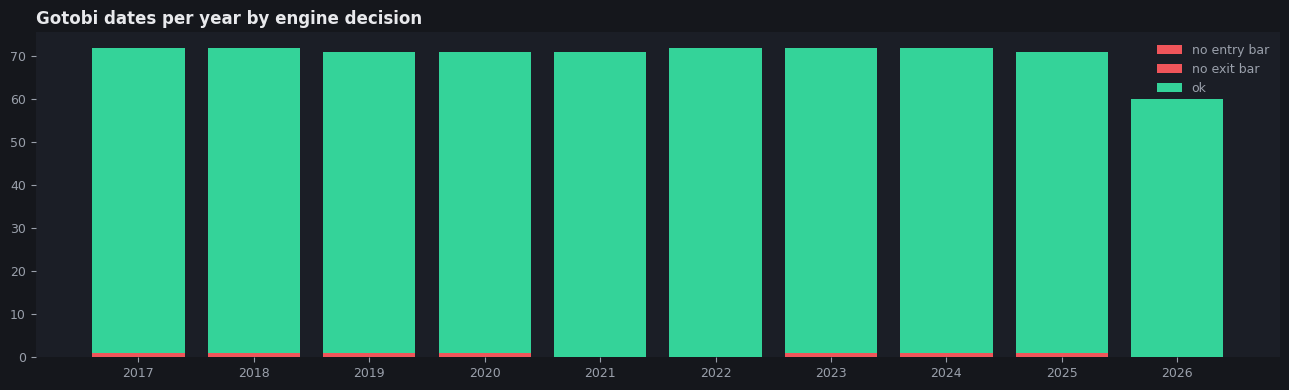

734,242 M5 bars | 2017-01-01 -> 2026-11-02 | 704 Gotobi dates | 697 trades
Decisions: {'ok': 697, 'no entry bar': 6, 'no exit bar': 1} | data loss: 0.99% (max 5%)
Engine validate(): {'weekly_structure': True, 'no_rollover': True, 'constant_window': True, 'no_overlap': True, 'mtm_reconciles': True, 'trades_per_year': True, 'entry_is_2230_utc': True, 'all_ok': True}
   [PASS] engine validate() all True
   [PASS] data loss (missing bars / spread) <= max_signal_loss  ->  0.99%
   [PASS] engine trades == signal_table takes  ->  697 vs 697


'PASS'

In [3]:
df_raw = eng.load_data(start=INS["start"], end=INS.get("end"))
a, b = (df_raw.index[0] + eng.JST).normalize(), (df_raw.index[-1] + eng.JST).normalize()
trades = eng.run_gotobi_backtest(df_raw)
sig = eng.signal_table(df_raw)
tpy = ACC["trades_per_year"]
val = eng.validate(df_raw, trades, expected_per_year=tuple(tpy) if np.ndim(tpy) else (66, 74))

DATA_LOSS = ["no entry bar", "no exit bar", "no spread"]
loss = sig["reason"].isin(DATA_LOSS).mean()
by_year = sig.groupby([sig.index.year, "reason"]).size().unstack(fill_value=0)
palette = {"ok": U.GREEN, "spread wide": U.ORANGE, "no entry bar": U.RED, "no exit bar": U.RED, "no spread": U.RED}

fig, ax = U.subplots(figsize=(13, 4), grid=False)
bottom = np.zeros(len(by_year))
for col in by_year.columns:
    ax.bar(by_year.index.astype(str), by_year[col], bottom=bottom, color=palette.get(col, U.SUB), label=col)
    bottom += by_year[col].to_numpy()
U.set_title(ax, "Gotobi dates per year by engine decision"); U.legend(ax, "upper right")
plt.tight_layout(); plt.show()

print(f"{len(df_raw):,} M5 bars | {df_raw.index[0]:%Y-%m-%d} -> {df_raw.index[-1]:%Y-%m-%d} | {len(sig)} Gotobi dates | {int(sig['take'].sum())} trades")
print("Decisions:", sig["reason"].value_counts().to_dict(), "| data loss:", f"{100 * loss:.2f}%", f"(max {100 * MAX_LOSS:.0f}%)")
print("Engine validate():", val)
C("2 Engine", "engine validate() all True", val["all_ok"], ", ".join(k for k, v in val.items() if not v and k != "all_ok"))
C("2 Engine", "data loss (missing bars / spread) <= max_signal_loss", loss <= MAX_LOSS, f"{100 * loss:.2f}%")
C("2 Engine", "engine trades == signal_table takes", len(trades) == int(sig["take"].sum()), f"{len(trades)} vs {int(sig['take'].sum())}")

In [4]:
hist_path = str(RUN_DIR / "gotobi_calendar_hist.csv")
eng.export_calendar(hist_path, a, b)
print("Calendario histórico escrito en:", hist_path)

Calendario histórico escrito en: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/USDJPY_Gotobi/runs/v1_axi_usdjpy/gotobi_calendar_hist.csv


## 3. INDEPENDENT CALENDAR CROSS-CHECK

The Gotobi calendar is the most error-prone piece (holidays, 31 Dec / 1-3 Jan, two nominal dates falling on the same day, month-end). `independent_gotobi_dates` rebuilds it with plain `datetime` and the `holidays` package; any difference is listed. It cannot be compared if the engine uses a custom holiday CSV or `extra_holidays`.

In [5]:
comparable = RULE["holiday_source"] == "holidays" and not RULE.get("extra_holidays")
cal = eng.gotobi_calendar(a, b)
eng_set = set(cal.index.date)
if comparable:
    ind_set = U.independent_gotobi_dates(a, b, days=tuple(RULE["gotobi_days"]), month_end=bool(RULE["include_month_end"]), shift_rule=RULE["shift_rule"])
    only_eng, only_ind = sorted(eng_set - ind_set), sorted(ind_set - eng_set)
    print(f"Engine {len(eng_set)} dates | independent {len(ind_set)} dates | only engine {len(only_eng)} | only independent {len(only_ind)}")
    diff = pd.DataFrame([(d, "engine only", cal.loc[pd.Timestamp(d), "label"]) for d in only_eng] + [(d, "independent only", "") for d in only_ind], columns=["date", "side", "label"])
    if len(diff):
        display(diff)
    C("3 Calendar", "engine calendar == independent calendar", not len(diff), f"{len(diff)} differences over {a:%Y}-{b:%Y}")
else:
    C("3 Calendar", "engine calendar == independent calendar", None, "custom holiday source: not comparable")
by_lab = cal.groupby("label").size().reindex([str(d) for d in RULE["gotobi_days"]] + (["EOM"] if RULE["include_month_end"] else []))
print("Dates per label:", by_lab.to_dict(), "| shifted:", int(cal["shifted"].sum()), "| weekday mix:", cal["dow"].value_counts().sort_index().to_dict())

Engine 704 dates | independent 704 dates | only engine 0 | only independent 0
   [PASS] engine calendar == independent calendar  ->  0 differences over 2017-2026
Dates per label: {'5': 114, '10': 118, '15': 118, '20': 118, '25': 118, 'EOM': 118} | shifted: 226 | weekday mix: {0: 92, 1: 100, 2: 105, 3: 106, 4: 301}


## 4. CLOCK, DST AND EA SPECIFICATION

The EA works in **MT5 server time** (GMT+2 winter / GMT+3 summer, US DST). For every trade the entry and exit must land on one constant clock time per season and on the **same calendar date as the JST date** (so the EA can index the calendar by server date). The table is the EA time spec.

In [6]:
sg = sig[sig["take"]]
expect = lambda t, off: hhmm((to_min(t) - 540 + 60 * off) % 1440)           # JST -> UTC -> server (UTC+off)
spec = pd.DataFrame({"season": sg["season"], "entry": sg["entry_server"].dt.strftime("%H:%M"), "exit": sg["exit_server"].dt.strftime("%H:%M"),
                     "date_ok": (sg["entry_server"].dt.normalize().to_numpy() == sg.index.to_numpy()) & (sg["exit_server"].dt.normalize().to_numpy() == sg.index.to_numpy())})
tab = spec.groupby("season").agg(trades=("entry", "size"), entry=("entry", lambda s: ",".join(sorted(s.unique()))),
                                 exit=("exit", lambda s: ",".join(sorted(s.unique()))), same_date_as_JST=("date_ok", "all"))
tab["expected entry"] = [expect(ET, 2 if s == "winter" else 3) for s in tab.index]
tab["expected exit"] = [expect(XT, 2 if s == "winter" else 3) for s in tab.index]
display(tab)

ix = df_raw.index[::997]
roundtrip = bool((eng.server_to_utc(eng.utc_to_server(ix)) == ix).all())
wk = eng.check_weekly_structure(df_raw)
dow_n = sg["dow"].value_counts().sort_index().to_dict()
print(f"Round-trip server<->UTC on {len(ix)} bars: {roundtrip} | weekly opens OK {100 * wk['ok_share']:.1f}% of {wk['weeks']} weeks | trades by JST weekday (0=Mon): {dow_n}")

C("4 Clock", "one entry/exit clock time per season, as expected", bool(((tab["entry"] == tab["expected entry"]) & (tab["exit"] == tab["expected exit"])).all()), f"entry {tab['entry'].to_dict()}")
C("4 Clock", "server date == JST date for entry and exit", bool(tab["same_date_as_JST"].all()))
C("4 Clock", "server<->UTC conversion round-trips", roundtrip)
C("4 Clock", "weekly-open structure >= 99%", wk["ok_share"] >= 0.99, f"{100 * wk['ok_share']:.1f}%")

EA_SPEC = dict(direction="long", gotobi_days=list(RULE["gotobi_days"]), month_end=bool(RULE["include_month_end"]), shift_rule=RULE["shift_rule"],
               entry_server_time=tab["entry"].to_dict(), exit_server_time=tab["exit"].to_dict(), bars_held=int(trades["bars"].iloc[0]),
               stop="none", spread_cap_axi_pips=None if np.isinf(cap0) else cap0, spread_cap_on_feed_spread_pips=None if np.isinf(cap0) else cap0 / SCALE,
               size_fraction=FRAC, hard_limit=HARD, calendar_csv=str(RUN_DIR / "gotobi_calendar_ea.csv"))
t0 = pd.Timestamp.today().normalize()
eng.export_calendar(EA_SPEC["calendar_csv"], t0, t0 + pd.Timedelta(days=400))
print("EA SPEC:"); display(pd.Series(EA_SPEC).to_frame("value"))
print("Calendar for the EA (next ~13 months) written to", EA_SPEC["calendar_csv"], "| feed spread cap = Axi cap / spread_scale when the EA runs on the raw feed (Strategy Tester).")

,trades,entry,exit,same_date_as_JST,expected entry,expected exit
season,,,,,,
summer,465,01:30,03:55,True,01:30,03:55
winter,232,00:30,02:55,True,00:30,02:55


Round-trip server<->UTC on 737 bars: True | weekly opens OK 100.0% of 509 weeks | trades by JST weekday (0=Mon): {0: 90, 1: 99, 2: 103, 3: 105, 4: 300}
   [PASS] one entry/exit clock time per season, as expected  ->  entry {'summer': '01:30', 'winter': '00:30'}
   [PASS] server date == JST date for entry and exit
   [PASS] server<->UTC conversion round-trips
   [PASS] weekly-open structure >= 99%  ->  100.0%
EA SPEC:


,value
direction,long
gotobi_days,"[5, 10, 15, 20, 25]"
month_end,True
shift_rule,previous
entry_server_time,"{'summer': '01:30', 'winter': '00:30'}"
exit_server_time,"{'summer': '03:55', 'winter': '02:55'}"
bars_held,29
stop,none
spread_cap_axi_pips,None
spread_cap_on_feed_spread_pips,None


Calendar for the EA (next ~13 months) written to /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/USDJPY_Gotobi/runs/v1_axi_usdjpy/gotobi_calendar_ea.csv | feed spread cap = Axi cap / spread_scale when the EA runs on the raw feed (Strategy Tester).


## 5. EA LOG VS ENGINE

Join by JST date (equal to the server date, section 4) inside the window covered by the log. Compared: **decision** (BUY vs `take`), **spread** at the entry bar (EA points -> pips vs the engine's *feed* spread; valid when the log comes from the MT5 Strategy Tester on the same history) and **reason**. Any date present on only one side is a failure: it means the EA calendar and the engine calendar disagree.

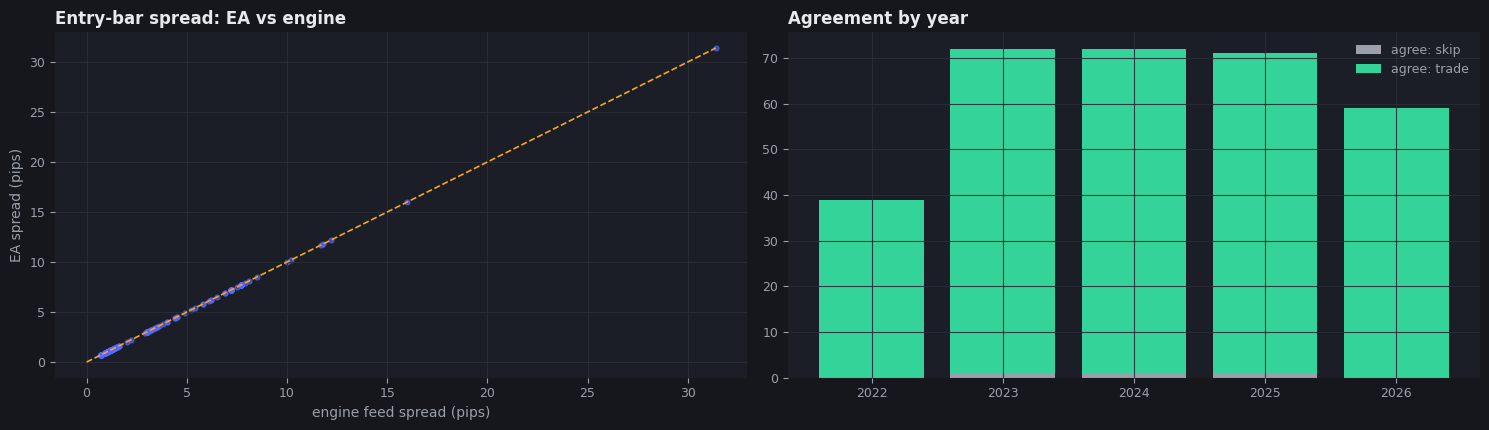

Log window 2022-06-20 -> 2026-10-23 | duplicated dates in log: 0 | EA trades 310 | engine trades in window 310
{'both': 313, 'left_only': 0, 'right_only': 0} | max spread diff: 0.000 pips
Reason crosstab (rows engine, columns EA):


reason_ea,calendar exception,no entry bar,ok
reason_eng,,,
no entry bar,0,2,0
no exit bar,1,0,0
ok,0,0,310


   [PASS] no duplicated dates in the log  ->  0 duplicates
   [PASS] no date present on only one side  ->  0 only engine, 0 only EA
   [PASS] decisions identical (BUY == take)  ->  0 differ of 313
   [PASS] spread difference <= 0.1 pips  ->  max 0.000


In [7]:
LOG = None
if LOG_PATH and Path(LOG_PATH).is_file():
    raw = pd.read_csv(LOG_PATH, sep=LOG_SEP, header=LOG_HEADER, names=LOG_COLS if LOG_HEADER is None else None)
    raw.index = pd.to_datetime(raw["date"]).dt.normalize()
    dup = int(raw.index.duplicated().sum())
    LOG = raw[~raw.index.duplicated(keep="last")].copy()
    LOG["spread_pips_ea"] = LOG["spread_points"] * float(eng.ENGINE_DEFAULTS["point_size"]) / float(eng.ENGINE_DEFAULTS["pip_size"])
    lo, hi = LOG.index.min(), LOG.index.max()
    ref = sig.loc[lo:hi, ["label", "shifted", "season", "spread_pips_feed", "reason", "take"]].rename(columns={"reason": "reason_eng"})
    j = ref.merge(LOG[["spread_pips_ea", "decision", "reason"]], left_index=True, right_index=True, how="outer", indicator=True).rename(columns={"reason": "reason_ea"})
    both = j[j["_merge"] == "both"].copy()
    both["agree"] = both["take"].astype(bool) == both["decision"].eq(LOG_BUY)
    both["d_spread"] = (both["spread_pips_ea"] - both["spread_pips_feed"]).abs()
    j["cat"] = np.select([j["_merge"] == "left_only", j["_merge"] == "right_only"], ["only engine", "only EA"],
                         np.where(j["take"].astype("boolean").fillna(False) == j["decision"].eq(LOG_BUY),
                                  np.where(j["take"].astype("boolean").fillna(False), "agree: trade", "agree: skip"), "decision differs"))
    cats = j.groupby([j.index.year, "cat"]).size().unstack(fill_value=0)
    cmap = {"agree: trade": U.GREEN, "agree: skip": U.SUB, "decision differs": U.RED, "only engine": U.ORANGE, "only EA": U.BLUE}

    fig, (ax1, ax2) = U.subplots(1, 2, figsize=(15, 4.4))
    ax1.scatter(both["spread_pips_feed"], both["spread_pips_ea"], s=12, color=U.BLUE, alpha=0.6)
    m = float(np.nanmax(both[["spread_pips_feed", "spread_pips_ea"]].to_numpy())) if len(both) else 1.0
    ax1.plot([0, m], [0, m], color=U.ORANGE, ls="--", lw=1.2)
    ax1.set_xlabel("engine feed spread (pips)", color=U.SUB); ax1.set_ylabel("EA spread (pips)", color=U.SUB); U.set_title(ax1, "Entry-bar spread: EA vs engine")
    bottom = np.zeros(len(cats))
    for col in cats.columns:
        ax2.bar(cats.index.astype(str), cats[col], bottom=bottom, color=cmap[col], label=col); bottom += cats[col].to_numpy()
    U.set_title(ax2, "Agreement by year"); U.legend(ax2, "upper right")
    plt.tight_layout(); plt.show()

    print(f"Log window {lo:%Y-%m-%d} -> {hi:%Y-%m-%d} | duplicated dates in log: {dup} | EA trades {int(LOG['decision'].eq(LOG_BUY).sum())} | engine trades in window {int(ref['take'].sum())}")
    print(j["_merge"].value_counts().to_dict(), "| max spread diff:", f"{both['d_spread'].max():.3f} pips")
    print("Reason crosstab (rows engine, columns EA):"); display(pd.crosstab(both["reason_eng"], both["reason_ea"]))
    bad = j[(j["cat"] != "agree: trade") & (j["cat"] != "agree: skip")]
    if len(bad):
        display(bad[["label", "season", "take", "decision", "reason_eng", "reason_ea", "spread_pips_feed", "spread_pips_ea", "_merge"]])
    C("5 EA log", "no duplicated dates in the log", dup == 0, f"{dup} duplicates")
    C("5 EA log", "no date present on only one side", bool((j["_merge"] == "both").all()), f"{int((j['_merge'] == 'left_only').sum())} only engine, {int((j['_merge'] == 'right_only').sum())} only EA")
    C("5 EA log", "decisions identical (BUY == take)", bool(both["agree"].all()), f"{int((~both['agree']).sum())} differ of {len(both)}")
    C("5 EA log", f"spread difference <= {SPREAD_TOL_PIPS:g} pips", bool((both["d_spread"].dropna() <= SPREAD_TOL_PIPS).all()), f"max {both['d_spread'].max():.3f}")
else:
    print(f"EA log not found ({LOG_PATH}): section skipped. Expected one row per Gotobi date with columns {LOG_COLS} (sep '{LOG_SEP}').")
    for n in ("no duplicated dates in the log", "no date present on only one side", "decisions identical (BUY == take)", f"spread difference <= {SPREAD_TOL_PIPS:g} pips"):
        C("5 EA log", n, None, "no log")

In [8]:
x = both[both["d_spread"] > SPREAD_TOL_PIPS]
print(len(x), "de", len(both))
print(both["d_spread"].describe(percentiles=[.5,.9,.99]))
display(x[["season","spread_pips_feed","spread_pips_ea","d_spread","decision"]].sort_values("d_spread", ascending=False).head(20))

0 de 313
count    311.0
mean       0.0
std        0.0
min        0.0
50%        0.0
90%        0.0
99%        0.0
max        0.0
Name: d_spread, dtype: float64


,season,spread_pips_feed,spread_pips_ea,d_spread,decision
date,,,,,


## 6. FILLS: EA DEALS VS ENGINE TRADES (OPTIONAL)

Engine fill model: buy at open + entry-bar spread, sell at the open. Slippage is measured against the engine's own entry and exit prices, **positive = worse for the strategy** (paid more on entry, received less on exit). Needs `DEALS_PATH`.

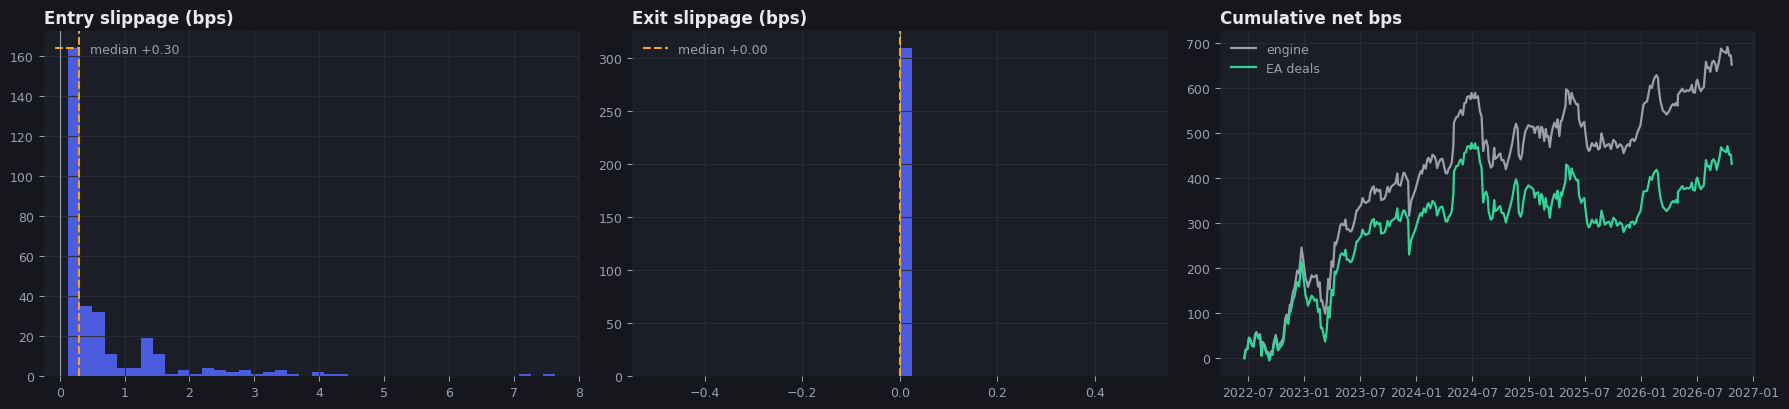

Deals window 2022-06-20 -> 2026-10-23 | engine trades in window 310 | EA deals 310
{'both': 310, 'left_only': 0, 'right_only': 0} | mean net: engine +2.10 bps | EA +1.39 bps
Median |time shift| entry 0.0 min, exit 0.0 min
   [PASS] every trade present on both sides  ->  0 unmatched
   [PASS] median |entry slippage| <= 1 bps  ->  0.30 bps
   [PASS] median |exit slippage| <= 1 bps  ->  0.00 bps
   [PASS] EA mean net within tolerance of engine  ->  -0.71 bps


In [9]:
if DEALS_PATH and Path(DEALS_PATH).is_file():
    d = pd.read_csv(DEALS_PATH, sep=DEAL_SEP).rename(columns={v: k for k, v in DEAL_COLS.items()})
    for c in ("entry_time", "exit_time"):
        d[c] = eng.server_to_utc(pd.DatetimeIndex(pd.to_datetime(d[c])), DEAL_TIME_MODE)
    d["entry_date"] = (d["entry_time"] + eng.JST).dt.normalize()

    # engine trades restricted to the window covered by the EA deals (tester / demo run)
    lo_d, hi_d = d["entry_date"].min(), d["entry_date"].max()
    tw = trades[(pd.to_datetime(trades["entry_date"]) >= lo_d) & (pd.to_datetime(trades["entry_date"]) <= hi_d)]

    m = tw.merge(d[["entry_date", "entry_time", "exit_time", "entry_price", "exit_price"]], on="entry_date", how="outer", suffixes=("_eng", "_ea"), indicator=True)
    mb = m[m["_merge"] == "both"].copy()
    mb["slip_in"] = (mb["entry_price_ea"] / mb["entry_price_eng"] - 1) * 1e4
    mb["slip_out"] = (1 - mb["exit_price_ea"] / mb["exit_price_eng"]) * 1e4
    mb["pnl_ea"] = (mb["exit_price_ea"] / mb["entry_price_ea"] - 1) * 1e4
    mb["d_entry_min"] = (mb["entry_time_ea"] - mb["entry_time_eng"]).dt.total_seconds() / 60
    mb["d_exit_min"] = (mb["exit_time_ea"] - mb["exit_time_eng"]).dt.total_seconds() / 60

    fig, (ax1, ax2, ax3) = U.subplots(1, 3, figsize=(18, 4.2))
    for ax, col, name in ((ax1, "slip_in", "Entry slippage (bps)"), (ax2, "slip_out", "Exit slippage (bps)")):
        ax.hist(mb[col], bins=40, color=U.BLUE, alpha=0.85); ax.axvline(0, color=U.SUB, lw=0.8)
        ax.axvline(mb[col].median(), color=U.ORANGE, ls="--", label=f"median {mb[col].median():+.2f}"); U.legend(ax); U.set_title(ax, name)
    ax3.plot(mb["entry_date"], mb["pnl_bps"].cumsum(), color=U.SUB, lw=1.6, label="engine")
    ax3.plot(mb["entry_date"], mb["pnl_ea"].cumsum(), color=U.GREEN, lw=1.6, label="EA deals"); U.legend(ax3); U.set_title(ax3, "Cumulative net bps")
    plt.tight_layout(); plt.show()
    print(f"Deals window {lo_d:%Y-%m-%d} -> {hi_d:%Y-%m-%d} | engine trades in window {len(tw)} | EA deals {len(d)}")
    print(m["_merge"].value_counts().to_dict(), "| mean net: engine", f"{mb['pnl_bps'].mean():+.2f}", "bps | EA", f"{mb['pnl_ea'].mean():+.2f}", "bps")
    print(f"Median |time shift| entry {mb['d_entry_min'].abs().median():.1f} min, exit {mb['d_exit_min'].abs().median():.1f} min")
    C("6 Fills", "every trade present on both sides", bool((m["_merge"] == "both").all()), f"{int((m['_merge'] != 'both').sum())} unmatched")
    C("6 Fills", f"median |entry slippage| <= {SLIP_TOL_BPS:g} bps", mb["slip_in"].abs().median() <= SLIP_TOL_BPS, f"{mb['slip_in'].abs().median():.2f} bps")
    C("6 Fills", f"median |exit slippage| <= {SLIP_TOL_BPS:g} bps", mb["slip_out"].abs().median() <= SLIP_TOL_BPS, f"{mb['slip_out'].abs().median():.2f} bps")
    C("6 Fills", "EA mean net within tolerance of engine", abs(mb["pnl_ea"].mean() - mb["pnl_bps"].mean()) <= 2 * SLIP_TOL_BPS, f"{mb['pnl_ea'].mean() - mb['pnl_bps'].mean():+.2f} bps")
else:
    print("No deals file (DEALS_PATH): section skipped.")
    for n in ("every trade present on both sides", f"median |entry slippage| <= {SLIP_TOL_BPS:g} bps", f"median |exit slippage| <= {SLIP_TOL_BPS:g} bps", "EA mean net within tolerance of engine"):
        C("6 Fills", n, None, "no deals file")

## 7. CFD LOT SIZING AT THE REAL CAPITAL

The research uses a continuous fraction of capital; the CFD trades in lots (`contract_size`, `min_lot`, `lot_step`). Here the strategy is replayed with **integer lots at `CAPITAL` and compounding**: effective fraction vs target, trades lost to the minimum lot, equity vs the ideal fractional equity, and the hard limit measured with the real lot sizes (intrabar).

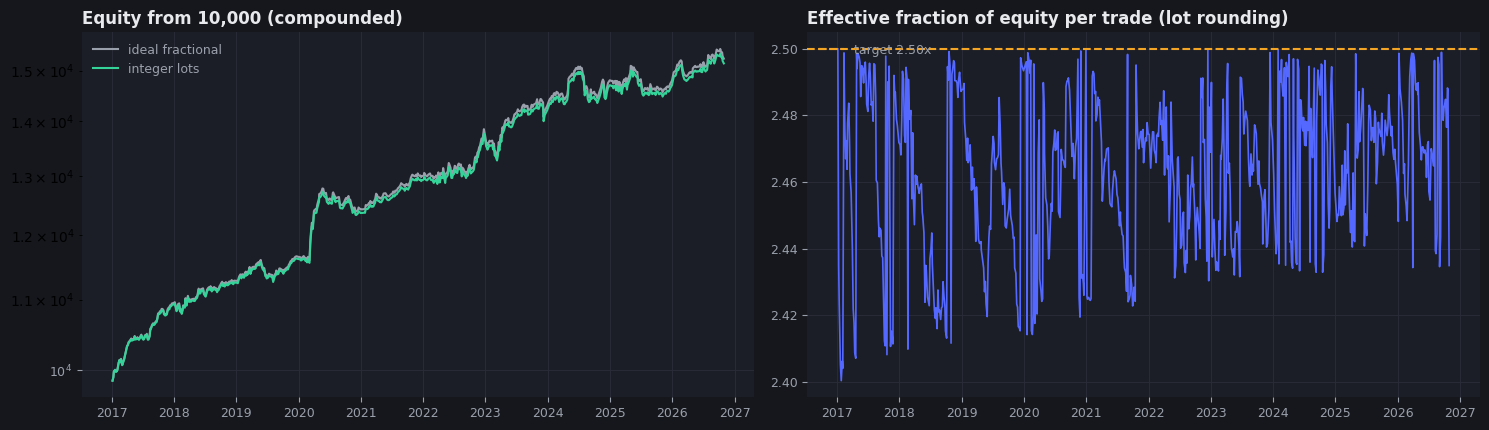

Lots: min 0.24 / median 0.32 / max 0.38 | effective fraction mean 2.462x vs target 2.50x (range 2.400-2.500)
Trades lost to the minimum lot: 0.0% | minimum capital for the target: 400 | final equity 15,146 vs ideal 15,243
Hard limit with real lots: intrabar max DD -5.10% (limit -9%) | trough 2024-09-04 23:35:00
   [PASS] capital >= minimum capital for the target fraction  ->  10,000 vs 400
   [PASS] trades lost to the minimum lot <= max_signal_loss  ->  0.0%
   [PASS] mean effective fraction within +-10% of target  ->  2.462x vs 2.50x
   [PASS] hard limit respected with integer lots (intrabar)  ->  -5.10% vs -9%


'PASS'

In [10]:
sizes = eng.cfd_trade_sizes(trades, CAPITAL, compounding=True)
min_cap = eng.min_capital_for_target(float(trades["entry_price"].iloc[-1]))
skipped = 1 - sizes["taken"].mean()
ideal = CAPITAL * (1 + FRAC * trades["pnl"].to_numpy() / 100).cumprod()
eff = sizes.loc[sizes["taken"], "size_fraction"]
rep = eng.hard_limit_report_intrabar(df_raw, trades, HARD, sizing=sizes["size_fraction"].to_numpy())
dt_ = pd.to_datetime(trades["entry_date"])

fig, (ax1, ax2) = U.subplots(1, 2, figsize=(15, 4.4))
ax1.plot(dt_, ideal, color=U.SUB, lw=1.5, label="ideal fractional"); ax1.plot(dt_, sizes["equity_after"], color=U.GREEN, lw=1.5, label="integer lots")
ax1.set_yscale("log"); U.legend(ax1); U.set_title(ax1, f"Equity from {CAPITAL:,.0f} (compounded)")
ax2.plot(dt_, sizes["size_fraction"], color=U.BLUE, lw=1.2); ax2.axhline(FRAC, color=U.ORANGE, ls="--", label=f"target {FRAC:.2f}x")
U.legend(ax2); U.set_title(ax2, "Effective fraction of equity per trade (lot rounding)")
plt.tight_layout(); plt.show()

print(f"Lots: min {sizes['lots'].min():.2f} / median {sizes['lots'].median():.2f} / max {sizes['lots'].max():.2f} | effective fraction mean {eff.mean():.3f}x vs target {FRAC:.2f}x (range {eff.min():.3f}-{eff.max():.3f})")
print(f"Trades lost to the minimum lot: {100 * skipped:.1f}% | minimum capital for the target: {min_cap:,.0f} | final equity {sizes['equity_after'].iloc[-1]:,.0f} vs ideal {ideal[-1]:,.0f}")
print(f"Hard limit with real lots: intrabar max DD {100 * rep['max_dd']:.2f}% (limit -{HARD:.0%}) | trough {rep['trough_date']}")
C("7 Lots", "capital >= minimum capital for the target fraction", CAPITAL >= min_cap, f"{CAPITAL:,.0f} vs {min_cap:,.0f}")
C("7 Lots", "trades lost to the minimum lot <= max_signal_loss", skipped <= MAX_LOSS, f"{100 * skipped:.1f}%")
C("7 Lots", "mean effective fraction within +-10% of target", bool(abs(eff.mean() / FRAC - 1) <= 0.10), f"{eff.mean():.3f}x vs {FRAC:.2f}x")
C("7 Lots", "hard limit respected with integer lots (intrabar)", rep["passed"], f"{100 * rep['max_dd']:.2f}% vs -{HARD:.0%}")

## 8. PASS / FAIL SUMMARY, VERDICT AND SAVE

In [11]:
chk = C.frame()
display(chk.style.map(lambda s: {"PASS": "color:#34d399", "FAIL": "color:#f0555a", "SKIP": "color:#f5a524"}.get(s, ""), subset=["status"]))
cnt = C.counts()
failed = chk.loc[chk["status"] == "FAIL", "name"].tolist()
skipped_ = chk.loc[chk["status"] == "SKIP", "name"].tolist()
ready = cnt["FAIL"] == 0
try:
    s03 = load_json(cfg, "03_validation.json")
    print(f"Notebook 03: ready_for_04={s03.get('ready_for_04')} | FAIL {s03['counts']['FAIL']} | carried from 02: {s03.get('carried_from_02')}")
except FileNotFoundError:
    s03 = None
    print("Notebook 03 results not found.")

print("=" * 80)
print(f"PASS {cnt['PASS']} | FAIL {cnt['FAIL']} | SKIP {cnt['SKIP']}")
print("OVERALL: " + ("PASS. Engine, calendar, clock and sizing reconcile." if ready else f"FAIL on {failed}. Fix the EA or the engine before going live; do not widen a tolerance to make it pass."))
if skipped_:
    print(f"Not verified (no input): {skipped_}. Provide the EA log / deals export to close them.")

save_json(cfg, "04_reconciliation.json", dict(
    ea_spec=EA_SPEC, engine=dict(trades=len(trades), dates=len(sig), data_loss=loss, validate=val),
    clock=tab.reset_index().to_dict("records"), lots=dict(capital=CAPITAL, min_capital=min_cap, skipped=skipped, eff_fraction_mean=eff.mean(), max_dd=rep["max_dd"]),
    ea_log_checked=LOG is not None, checks=C.items, counts=cnt, ready_for_live=ready and not skipped_))

,section,name,status,detail
0,2 Engine,engine validate() all True,PASS,
1,2 Engine,data loss (missing bars / spread) <= max_signal_loss,PASS,0.99%
2,2 Engine,engine trades == signal_table takes,PASS,697 vs 697
3,3 Calendar,engine calendar == independent calendar,PASS,0 differences over 2017-2026
4,4 Clock,"one entry/exit clock time per season, as expected",PASS,"entry {'summer': '01:30', 'winter': '00:30'}"
5,4 Clock,server date == JST date for entry and exit,PASS,
6,4 Clock,server<->UTC conversion round-trips,PASS,
7,4 Clock,weekly-open structure >= 99%,PASS,100.0%
8,5 EA log,no duplicated dates in the log,PASS,0 duplicates
9,5 EA log,no date present on only one side,PASS,"0 only engine, 0 only EA"


Notebook 03: ready_for_04=False | FAIL 4 | carried from 02: ['N in-sample >= n_min', 'plateau (3x3, PF >= pf_min, N >= n_min)', 'mean net > 0 in every Gotobi label']
PASS 20 | FAIL 0 | SKIP 0
OVERALL: PASS. Engine, calendar, clock and sizing reconcile.
Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/USDJPY_Gotobi/runs/v1_axi_usdjpy/04_reconciliation.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/USDJPY_Gotobi/runs/v1_axi_usdjpy/04_reconciliation.json')